# Q4

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import requests
from io import BytesIO

# Set random seed
torch.manual_seed(42)
np.random.seed(42)

# 1. Download sample images
image_paths = ["mona.jpg", "cat.jpg", "liberty.jpg", "nyc.jpg", "cornell.jpg"]

images = []
for path in image_paths:
    img = Image.open(path).convert('RGB').resize((128, 128))
    images.append(img)

In [ ]:
# 2. Define the schedule parameters for forward diffusion
T = 1000
beta = torch.linspace(1e-4, 0.02, T) # Linear schedule
alpha = 1.0 - beta
alpha_bar = torch.cumprod(alpha, dim=0)

def q_sample(x0, t, noise=None):
    """
    Diffuse the data x0 to time step t using the closed-form formula:
    q(x_t | x_0) = N(x_t; sqrt(alpha_bar_t) * x_0, (1 - alpha_bar_t) * I)
    """
    if noise is None:
        noise = torch.randn_like(x0)

    # Get alpha_bar value corresponding to time step t for each batch item
    ab_t = alpha_bar[t].view(-1, 1, 1, 1)

    # Calculate mean and variance coefficients
    mean_coef = torch.sqrt(ab_t)
    noise_coef = torch.sqrt(1.0 - ab_t)

    return mean_coef * x0 + noise_coef * noise

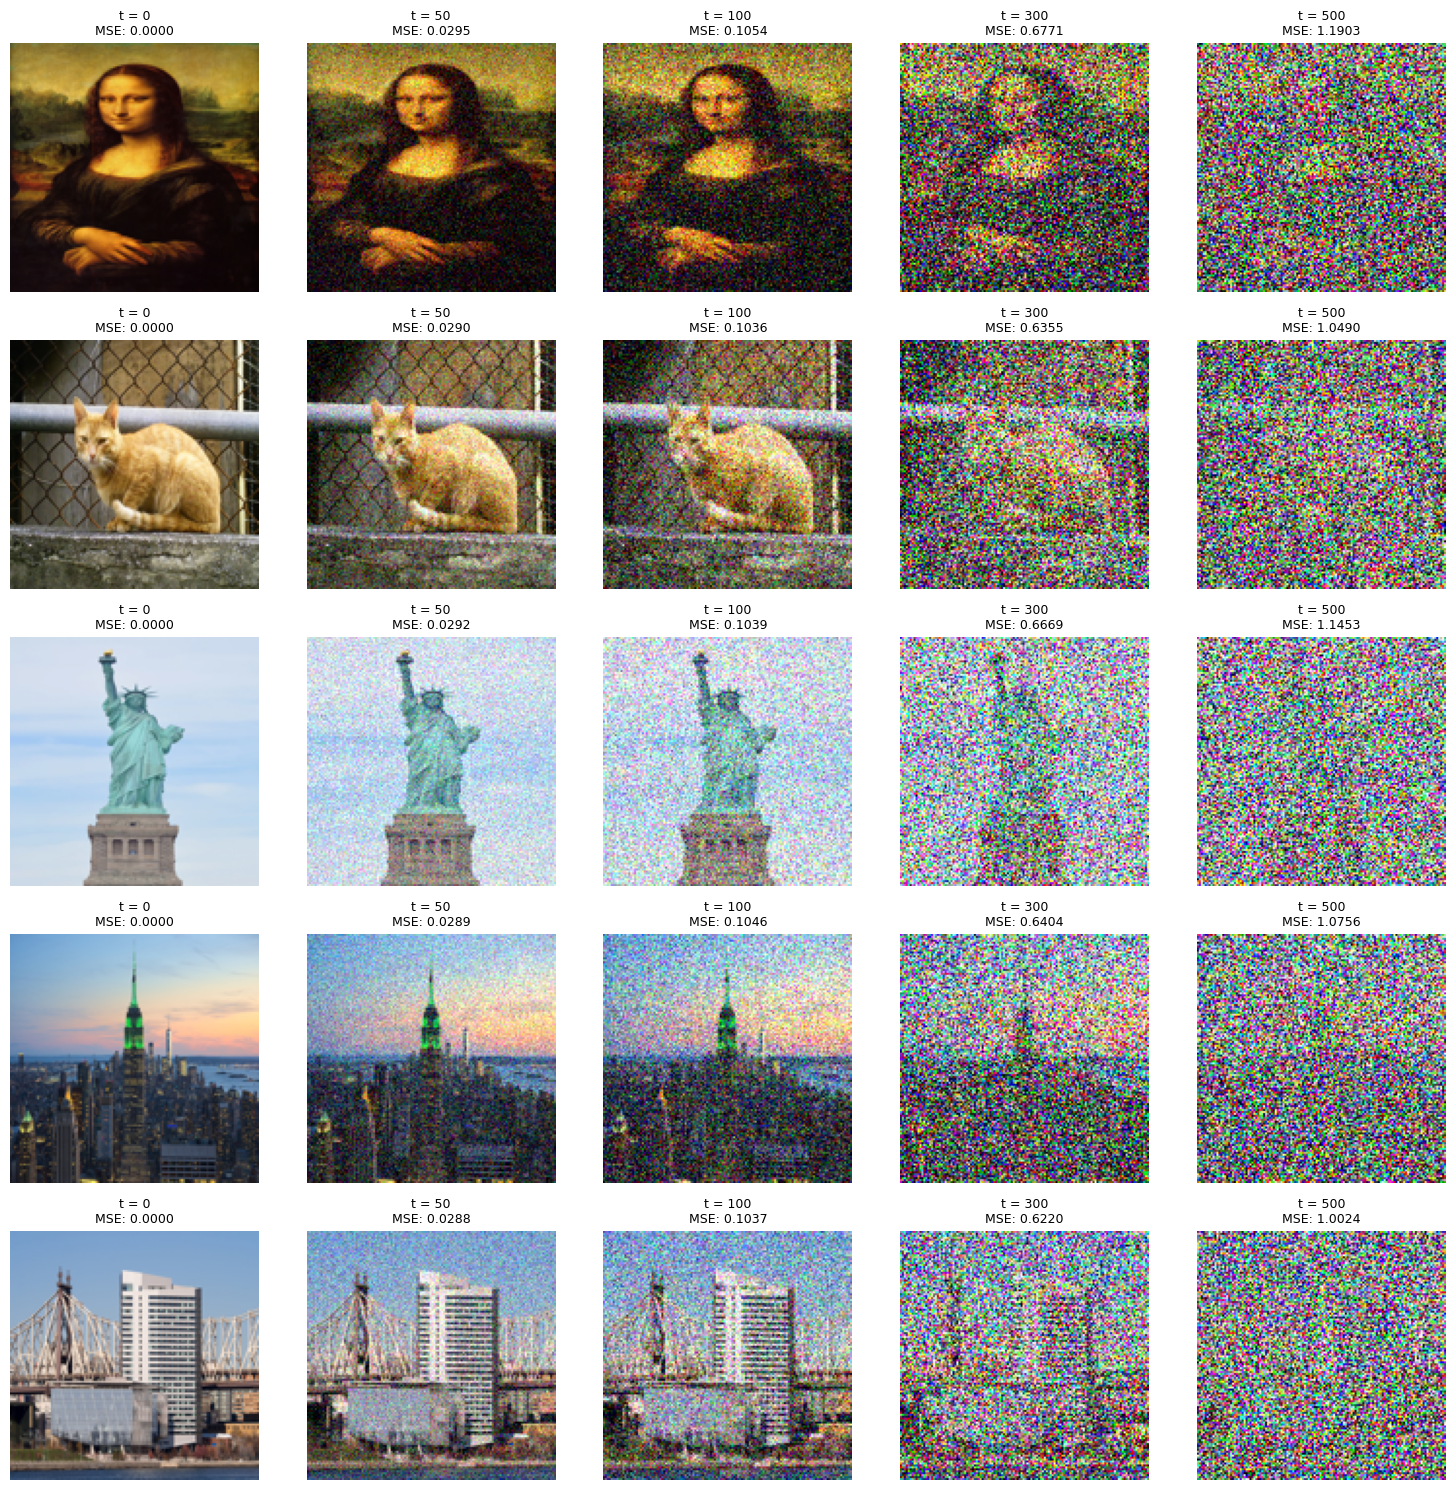

In [ ]:
# 3. Corrupt images at different time steps and plot
time_steps = [0, 50, 100, 300, 500]
num_images = len(images)

# Convert images to a PyTorch tensor with shape (num_images, 3, 128, 128) and normalized to [-1, 1]
x0 = torch.stack([torch.tensor(np.array(img)).permute(2, 0, 1).float() / 127.5 - 1.0 for img in images])

fig, axes = plt.subplots(num_images, len(time_steps), figsize=(15, 3 * num_images))

for i in range(num_images):
    single_x0 = x0[i:i+1] # Keep batch dimension: (1, 3, 128, 128)
    for j, t in enumerate(time_steps):
        if t == 0:
            xt = single_x0
            mse = 0.0
        else:
            # Generate noise and diffuse
            noise = torch.randn_like(single_x0)
            xt = q_sample(single_x0, torch.tensor([t-1]), noise=noise)
            # Compute MSE between original and noisy image in normalized space
            mse = torch.mean((xt - single_x0) ** 2).item()

        # Denormalize to display [0, 1]
        img_to_show = ((xt[0].permute(1, 2, 0) + 1.0) / 2.0).clamp(0, 1).numpy()
        ax = axes[i, j]
        ax.imshow(img_to_show)
        ax.axis('off')
        ax.set_title(f"t = {t}\nMSE: {mse:.4f}", fontsize=9)
plt.tight_layout()
plt.show()

# Q5

In [ ]:
!pip install diffusers torch accelerate

Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

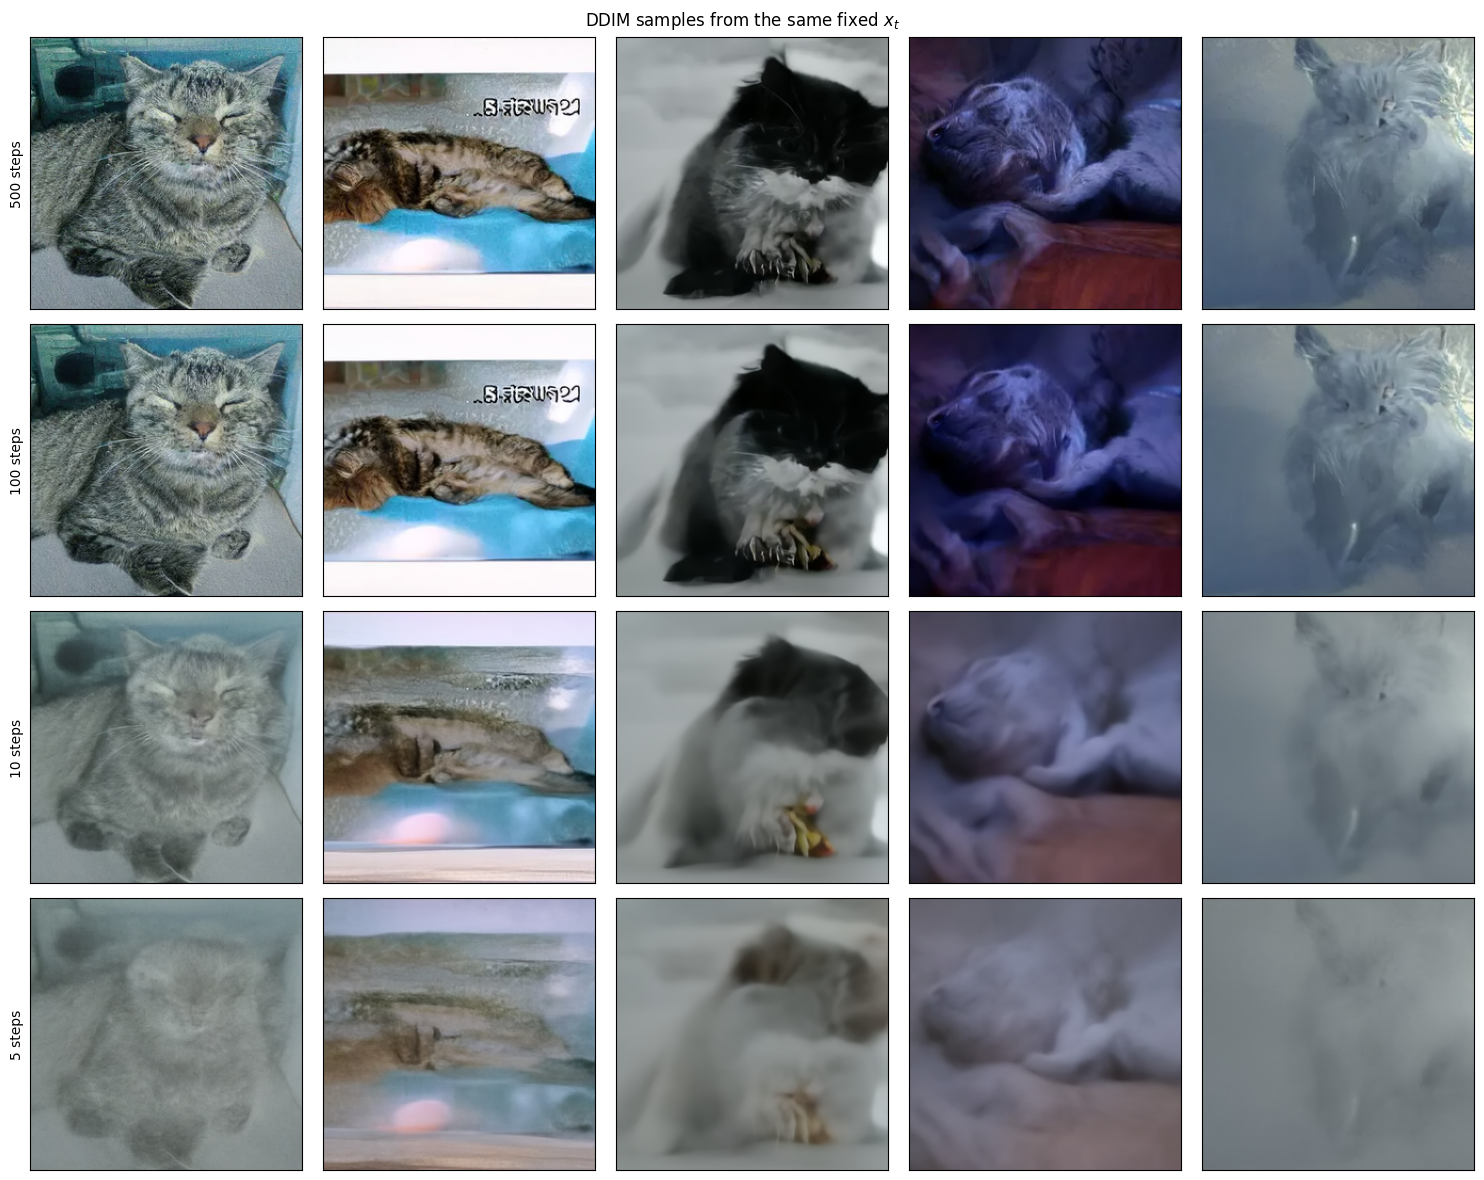

In [ ]:
from diffusers import DDIMPipeline
device = "cuda" if torch.cuda.is_available() else "cpu"

# model_id = "google/ddpm-cifar10-32"
model_id = "google/ddpm-cat-256"

# load model and scheduler
ddim = DDIMPipeline.from_pretrained(model_id).to(device)

steps_list = [500, 100, 10, 5]
n = 5

results = {}
for s in steps_list:
    g = torch.Generator(device).manual_seed(6)
    results[s] = ddim(batch_size=n, num_inference_steps=s, eta=0.0, generator=g).images

fig, axes = plt.subplots(len(steps_list), n, figsize=(3 * n, 3 * len(steps_list)))
for r, s in enumerate(steps_list):
    for c in range(n):
        axes[r, c].imshow(results[s][c])
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(f"{s} steps")
plt.suptitle("DDIM samples from the same fixed $x_t$")
plt.tight_layout()
plt.show()

We use the pretrained google/ddpm-cat-256 model with the DDIM sampler and test 500, 100, 10, and 5 sampling steps. All experiments use the same initial noise x_T and random seed.

The results with 500 and 100 steps are almost identical, with the same cat poses, colors, backgrounds, and fine details. This shows that DDIM can significantly reduce the number of sampling steps without affecting image quality. With 10 steps, the overall structure remains similar, but the images become blurry and lose details such as fur texture and whiskers. With only 5 steps, the quality drops significantly, and the cats become barely recognizable.

Overall, DDIM can generate high-quality images with 50–100 steps, much fewer than the 1000 steps used by DDPM. However, when the number of steps is too small, the sampling process becomes less accurate, resulting in blurry images and loss of detail.